# V4 Mini-BERT + User History — Final internal TEST evaluation (NO TRAINING)

این نوت‌بوک **بدون آموزش مجدد**، مدل ذخیره‌شدهٔ V4 را روی **مجموعهٔ Test داخلی با برچسب** ارزیابی می‌کند. همهٔ داده‌ها و مدل از همان اجرای V4 در Google Drive خوانده می‌شوند.

- **SEED = 42**؛ از فایل `splits/test.parquet` ذخیره‌شده استفاده می‌شود؛ **split جدید ساخته نمی‌شود**.
- تعداد مورد انتظار **62,921** نمونهٔ Test (مستقل از Validation) است. دادهٔ اصلی `test_data.csv` بدون برچسبِ مسابقه مدنظر این ارزیابی نیست.
- متن دقیقاً با قانون قبلی 256 توکن (برای متن بلند: `summary + review`، 191 توکن ابتدایی + 63 توکن انتهایی محتوا) پردازش می‌شود و dynamic padding مضرب 8 دارد.
- ویژگی‌های `past_mean` و `past_count` از خروجی ذخیره‌شدهٔ همان اجرای V4 خوانده و در برابر بانک تاریخچهٔ **فقط Train** راستی‌آزمایی می‌شوند.
- کد، `model.eval()` و `torch.inference_mode()` را اجرا می‌کند، **هیچ** `train()`، optimizer یا gradient update ندارد.

**راهنما:** در Google Colab یک Runtime با GPU (ترجیحاً T4) انتخاب کنید و سلول‌ها را از ابتدا به‌ترتیب اجرا کنید. اگر پوشهٔ اجرای اصلی را جابه‌جا کرده‌اید، فقط `SOURCE_RUN_DIR` را در سلول تنظیمات تغییر دهید. خروجی‌ها در پوشهٔ جدیدی در Drive ذخیره می‌شوند و فایل‌های مدل تغییر نمی‌کنند.

## ۱) نصب وابستگی‌ها — همان نسخهٔ `transformers` اجرای اصلی

In [1]:
%pip install -q "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" "pandas>=2.2,<4" scikit-learn pyarrow matplotlib tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## ۲) اتصال Drive و انتخاب همان اجرای V4

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, time, importlib.util, sys

import numpy as np
import pandas as pd
import torch
from transformers import set_seed
from google.colab import drive

drive.mount('/content/drive')

# SAME SEED as the source notebook. No resampling or new split is performed.
SEED = 42
set_seed(SEED)

SOURCE_RUN_DIR = Path(
    '/content/drive/MyDrive/amazon_sentiment/experiments_history/'
    '20261105_165318_432545'
)
BEST_MODEL_DIR = SOURCE_RUN_DIR / 'best_model'
SPLITS_DIR = SOURCE_RUN_DIR / 'splits'
TEST_PATH = SPLITS_DIR / 'test.parquet'
TEST_HISTORY_PATH = SOURCE_RUN_DIR / 'test_history_features.parquet'
HISTORY_BANK_PATH = SOURCE_RUN_DIR / 'history_bank.parquet'
MANIFEST_PATH = SPLITS_DIR / 'split_manifest.json'
HISTORY_POLICY_PATH = SOURCE_RUN_DIR / 'history_policy.json'
SELECTED_MODEL_PATH = SOURCE_RUN_DIR / 'selected_model.json'
MODEL_SOURCE_PATH = BEST_MODEL_DIR / 'history_model.py'
PREPROCESSING_PATH = BEST_MODEL_DIR / 'input_preprocessing.json'

EXPECTED_TEST_SIZE = 62_921  # Recorded by the uploaded V4 notebook.
EVAL_BATCH_SIZE = 128       # Same evaluation batch size as the original run.

needed = [TEST_PATH, TEST_HISTORY_PATH, HISTORY_BANK_PATH, MANIFEST_PATH,
          HISTORY_POLICY_PATH, SELECTED_MODEL_PATH, MODEL_SOURCE_PATH,
          PREPROCESSING_PATH, BEST_MODEL_DIR / 'config.json']
missing = [str(p) for p in needed if not p.is_file()]
if not (BEST_MODEL_DIR / 'model.safetensors').is_file() and not (BEST_MODEL_DIR / 'pytorch_model.bin').is_file():
    missing.append(str(BEST_MODEL_DIR / '[model.safetensors OR pytorch_model.bin]'))
if missing:
    raise FileNotFoundError('Missing saved V4 files in Drive:\n' + '\n'.join(missing))

manifest = json.loads(MANIFEST_PATH.read_text())
history_policy = json.loads(HISTORY_POLICY_PATH.read_text())
selected = json.loads(SELECTED_MODEL_PATH.read_text())
preprocessing = json.loads(PREPROCESSING_PATH.read_text())

assert manifest['seed'] == SEED, 'The saved test split was produced with another seed.'
assert manifest['sizes']['test'] == EXPECTED_TEST_SIZE, 'The saved run has an unexpected test size.'
assert manifest['ratios'] == [0.70, 0.15, 0.15], 'Saved split proportions differ from the source.'
assert selected['split_fingerprint'] == manifest['split_fingerprint'], 'Selected model and split differ.'
assert history_policy['split_fingerprint'] == manifest['split_fingerprint'], 'History and split differ.'
assert history_policy['source'] == 'V2 train split only', 'Unexpected history source.'
assert history_policy['strictly_before'] is True, 'History must only use earlier UTC dates.'
assert history_policy['time_unit'] == 'UTC day', 'The history time policy changed.'

RUN_STAMP = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
OUTPUT_DIR = SOURCE_RUN_DIR / 'test_evaluations' / RUN_STAMP
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Source model:', BEST_MODEL_DIR)
print('TEST split:', TEST_PATH)
print('Seed:', SEED, '| Expected test rows:', EXPECTED_TEST_SIZE)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '(CPU: slower)')
print('Output directory:', OUTPUT_DIR)

Mounted at /content/drive
Source model: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/best_model
TEST split: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/splits/test.parquet
Seed: 42 | Expected test rows: 62921
Device: cuda Tesla T4
Output directory: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/test_evaluations/20261106_164036_511639


## ۳) خواندن TEST ذخیره‌شده؛ کنترل جدابودن از Train و Validation و یکسان‌بودن History

In [3]:
# Reading source_row_id alone from train/validation is enough to confirm exact saved split membership.
ids_by_split = {}
for split in ['train', 'validation', 'test']:
    path = SPLITS_DIR / f'{split}.parquet'
    if not path.is_file():
        raise FileNotFoundError(f'Saved {split} split is missing: {path}')
    ids = pd.read_parquet(path, columns=['source_row_id'])['source_row_id'].to_numpy(dtype=np.int64)
    assert len(ids) == manifest['sizes'][split], f'Incorrect number of saved {split} rows.'
    assert len(np.unique(ids)) == len(ids), f'Duplicate row IDs in {split}.'
    ids_by_split[split] = ids

assert all(
    np.intersect1d(ids_by_split[a], ids_by_split[b]).size == 0
    for a,b in [('train','validation'), ('train','test'), ('validation','test')]
), 'The saved splits overlap by source_row_id!'

# Reproduce the V4 split fingerprint, including each split's row IDs.
computed_fingerprint = hashlib.sha256(b''.join(
    np.sort(ids_by_split[name]).tobytes()
    for name in ['train','validation','test']
)).hexdigest()
assert computed_fingerprint == manifest['split_fingerprint'], 'Saved splits do not match the original run.'

test_df = pd.read_parquet(TEST_PATH).reset_index(drop=True)
required_columns = {'source_row_id','reviewText','summary','labels','user','day'}
assert required_columns.issubset(test_df.columns), f'Missing columns: {required_columns - set(test_df.columns)}'
assert len(test_df) == EXPECTED_TEST_SIZE
assert np.array_equal(test_df.source_row_id.to_numpy(dtype=np.int64), ids_by_split['test'])
assert test_df.labels.notna().all()
assert test_df.labels.astype(int).isin(range(5)).all(), 'Labels must be encoded 0..4.'
if 'overall' in test_df:
    assert (test_df['overall'].astype(int) == test_df.labels.astype(int) + 1).all()
assert test_df.reviewText.notna().all() and test_df.reviewText.astype(str).str.strip().ne('').all()

# Retrieve exactly the history features written when the model was trained.
feature_df = pd.read_parquet(TEST_HISTORY_PATH)
assert len(feature_df) == EXPECTED_TEST_SIZE
assert feature_df.source_row_id.is_unique
assert {'source_row_id','past_mean','past_count'}.issubset(feature_df.columns)

test_df = test_df.merge(feature_df[['source_row_id','past_mean','past_count']],
                        on='source_row_id', how='left', validate='one_to_one',
                        sort=False, indicator=True)
assert test_df['_merge'].eq('both').all(), 'Some test rows have no saved history features.'
test_df.drop(columns=['_merge'], inplace=True)
assert np.isfinite(test_df.past_mean).all()
assert (test_df.past_count >= 0).all()
assert ((test_df.past_mean >= 1) & (test_df.past_mean <= 5)).all()
assert np.all(test_df.loc[test_df.past_count.eq(0), 'past_mean'].to_numpy() == 3.)

# The following is an independent verification using the SOURCE notebook's exact logic:
# earlier UTC day + SAME USER + Train-only history bank, with no use of test labels.
def attach_history(query, bank):
    base = query[['source_row_id','user','day']].reset_index(drop=True).copy()
    base['_position'] = np.arange(len(base))
    known = base.dropna(subset=['user','day'])
    if len(known) and len(bank):
        right = bank.rename(columns={'day':'matched_day'})
        matches = pd.merge_asof(
            known.sort_values('day'), right.sort_values('matched_day'),
            left_on='day', right_on='matched_day', by='user',
            direction='backward', allow_exact_matches=False
        )
        assert (matches.loc[matches.matched_day.notna(),'matched_day'] <
                matches.loc[matches.matched_day.notna(),'day']).all()
        base = base.merge(matches[['_position','past_count','past_sum']],
                          on='_position',how='left',validate='one_to_one').sort_values('_position')
    else:
        base['past_count'] = 0
        base['past_sum'] = 0.
    count = base['past_count'].fillna(0).to_numpy(dtype='int64')
    sums = base['past_sum'].fillna(0).to_numpy(dtype='float64')
    mean = np.divide(sums,count,out=np.full(len(base),3.0),where=count>0)
    result = query.reset_index(drop=True).copy()
    result['past_count'] = count
    result['past_mean'] = mean.astype('float32')
    return result

history_bank = pd.read_parquet(HISTORY_BANK_PATH)
assert len(history_bank) == history_policy['history_bank_rows']
recomputed_features = attach_history(test_df[['source_row_id','user','day']], history_bank)
assert np.array_equal(recomputed_features.past_count.to_numpy(), test_df.past_count.to_numpy()), 'History counts changed.'
assert np.allclose(recomputed_features.past_mean, test_df.past_mean, atol=1e-6), 'History means changed.'
del history_bank, recomputed_features

print('Verified TEST membership and seed:', SEED)
print('TEST / VALIDATION disjoint:', True)
print('TEST rows:', len(test_df), '| With history:', int(test_df.past_count.gt(0).sum()))
print('History correctly reconstructed from saved TRAIN bank only.')
print('Ratings in TEST:')
print((test_df.labels + 1).value_counts().sort_index().rename('count').to_string())

Verified TEST membership and seed: 42
TEST / VALIDATION disjoint: True
TEST rows: 62921 | With history: 19969
History correctly reconstructed from saved TRAIN bank only.
Ratings in TEST:
labels
1     6222
2     4256
3     6093
4    11739
5    34611


## ۴) بارگذاری مدل آموزش‌دیده و Tokenizer از Google Drive (بدون Train)

In [4]:
from transformers import AutoTokenizer

# The original V4 model uses a custom Python class, NOT standard AutoModel.
spec = importlib.util.spec_from_file_location('history_model', MODEL_SOURCE_PATH)
history_module = importlib.util.module_from_spec(spec)
sys.modules['history_model'] = history_module
spec.loader.exec_module(history_module)
HistoryBertForSequenceClassification = history_module.HistoryBertForSequenceClassification

# Keep exactly the saved tokenizer/vocabulary, rather than redownloading the base model.
tokenizer = AutoTokenizer.from_pretrained(str(BEST_MODEL_DIR), local_files_only=True)
model = HistoryBertForSequenceClassification.from_pretrained(
    str(BEST_MODEL_DIR), local_files_only=True
)
model = model.to(DEVICE)
model.eval() # no dropout, no optimization

assert model.config.num_labels == 5
assert abs(float(model.config.alpha_cap) - float(selected['alpha_cap'])) < 1e-9
assert abs(float(model.config.alpha_cap) - 0.20) < 1e-9
assert tokenizer.num_special_tokens_to_add(pair=False) == 2

print('Loaded trained V4 model successfully (NO retraining).')
print('Alpha cap:', model.config.alpha_cap)
print('Parameters:', f'{sum(p.numel() for p in model.parameters()):,}')

Loaded trained V4 model successfully (NO retraining).
Alpha cap: 0.2
Parameters: 11,176,140


## ۵) توکن‌سازی دقیقاً مطابق نوت‌بوک اصلی و آماده‌سازی Batch

In [5]:
from datasets import Dataset
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

MAX_LENGTH = preprocessing['max_length']
HEAD_TOKENS = preprocessing['head_tokens_with_cls']
TAIL_TOKENS = preprocessing['tail_tokens_with_sep']
SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(pair=False)
CONTENT_LIMIT = MAX_LENGTH - SPECIAL_TOKENS
HEAD_CONTENT = HEAD_TOKENS - 1   # [CLS] belongs to head segment.
TAIL_CONTENT = TAIL_TOKENS - 1   # [SEP] belongs to tail segment.

assert (MAX_LENGTH,HEAD_TOKENS,TAIL_TOKENS,SPECIAL_TOKENS) == (256,192,64,2)
assert HEAD_CONTENT + TAIL_CONTENT == CONTENT_LIMIT
assert preprocessing['short_input'] == 'reviewText_only'
assert preprocessing['long_input'] == 'summary + single_space + reviewText'
assert preprocessing['dynamic_padding'] is True
assert preprocessing['pad_to_multiple_of'] == 8

def select_content_ids(review_ids, combined_ids=None):
    if len(review_ids) <= CONTENT_LIMIT:
        return list(review_ids)
    if combined_ids is None or len(combined_ids) <= CONTENT_LIMIT:
        raise ValueError('A long review requires complete combined token IDs.')
    return list(combined_ids[:HEAD_CONTENT]) + list(combined_ids[-TAIL_CONTENT:])

def wrap_content_ids(content_ids):
    input_ids = tokenizer.build_inputs_with_special_tokens(content_ids)
    token_type_ids = tokenizer.create_token_type_ids_from_sequences(content_ids)
    assert len(input_ids) <= MAX_LENGTH
    return {'input_ids': input_ids, 'attention_mask':[1]*len(input_ids),
            'token_type_ids':token_type_ids}

def tokenize_batch(batch):
    # Exact source-V4 preprocessing: no stopword removal, no decode/re-encode.
    reviews = [str(text).strip() for text in batch['reviewText']]
    summaries = [str(text).strip() for text in batch['summary']]
    review_ids = tokenizer(reviews, add_special_tokens=False, truncation=False,
                           padding=False, verbose=False)['input_ids']
    long_indices = [i for i,ids in enumerate(review_ids) if len(ids) > CONTENT_LIMIT]
    combined_by_index = {}
    if long_indices:
        combined = [(summaries[i]+' '+reviews[i]).strip() for i in long_indices]
        combined_ids = tokenizer(combined, add_special_tokens=False, truncation=False,
                                 padding=False, verbose=False)['input_ids']
        combined_by_index = dict(zip(long_indices, combined_ids))
    output = {'input_ids':[], 'attention_mask':[], 'token_type_ids':[]}
    for i,ids in enumerate(review_ids):
        example = wrap_content_ids(select_content_ids(ids, combined_by_index.get(i)))
        for key in output:
            output[key].append(example[key])
    return output

# Verify a few boundary conditions, identical to the training notebook.
assert select_content_ids(list(range(254)), [999]*400) == list(range(254))
assert select_content_ids(list(range(255)),list(range(500))) == list(range(191))+list(range(437,500))
assert tokenizer('good product')['input_ids'] == tokenize_batch(
    {'reviewText':['good product'], 'summary':['ignored summary']})['input_ids'][0]

# ONLY test rows are tokenized. No Train or Validation inputs are evaluated.
raw_test = Dataset.from_pandas(
    test_df[['reviewText','summary','labels','past_mean','past_count']],
    preserve_index=False
)
tokenized_test = raw_test.map(
    tokenize_batch, batched=True, batch_size=256,
    remove_columns=['reviewText','summary'],
    desc='Tokenizing ONLY the saved internal TEST'
)
assert len(tokenized_test) == EXPECTED_TEST_SIZE

text_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
class HistoryCollator:
    def __call__(self, examples):
        history = torch.tensor(
            [[float(e.get('past_mean',3.0)), float(e.get('past_count',0))] for e in examples],
            dtype=torch.float32
        )
        examples = [
            {k:v for k,v in e.items() if k not in ['past_mean','past_count']}
            for e in examples
        ]
        batch = text_collator(examples)
        batch['history_features'] = history
        return batch

test_loader = DataLoader(
    tokenized_test, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=0, collate_fn=HistoryCollator()
)
print('Ready for inference on', len(tokenized_test), 'TEST examples.')

Tokenizing ONLY the saved internal TEST:   0%|          | 0/62921 [00:00<?, ? examples/s]

Ready for inference on 62921 TEST examples.


## ۶) Inference فقط روی TEST، همراه با محاسبهٔ وزن مؤثر History

In [6]:
from tqdm.auto import tqdm

all_true, all_log_probs, all_alpha = [], [], []
start = time.perf_counter()

# No .train(), no backward(), no optimizer. This reproduces the original model.forward()
# while ALSO collecting alpha_effective, which the standard forward() does not return.
model.eval()
with torch.inference_mode():
    for batch_index, batch in enumerate(tqdm(test_loader, desc='Evaluating internal TEST')):
        y = batch.pop('labels').to(DEVICE)
        batch = {k: v.to(DEVICE) for k,v in batch.items()}
        with torch.autocast(device_type='cuda', dtype=torch.float16,
                            enabled=(DEVICE.type=='cuda')):
            encoded = model.bert(
                input_ids=batch['input_ids'],
                attention_mask=batch['attention_mask'],
                token_type_ids=batch.get('token_type_ids'),
                return_dict=True
            )
            pooled = encoded.pooler_output
            text_logits = model.classifier(model.dropout(pooled))
            log_probs, alpha_effective = model.mix_with_history(
                pooled, text_logits, batch['history_features']
            )

        # Sanity check: equivalent to the model's saved forward() on the first batch.
        if batch_index == 0:
            with torch.autocast(device_type='cuda', dtype=torch.float16,
                                enabled=(DEVICE.type=='cuda')):
                direct_log_probs = model(**batch).logits
            assert torch.allclose(log_probs, direct_log_probs, atol=2e-5, rtol=2e-5), \
                'Manual inference differs from saved model.forward.'

        all_true.append(y.cpu().numpy())
        all_log_probs.append(log_probs.float().cpu().numpy())
        all_alpha.append(alpha_effective.float().cpu().numpy())

elapsed_seconds = time.perf_counter() - start
y_true_idx = np.concatenate(all_true).astype(np.int64)
log_probs = np.concatenate(all_log_probs).astype(np.float64)
alpha_values = np.concatenate(all_alpha).astype(np.float64)

assert len(y_true_idx) == len(test_df) == EXPECTED_TEST_SIZE
assert np.array_equal(y_true_idx, test_df.labels.to_numpy(dtype=np.int64)), 'Inference row order changed!'
assert log_probs.shape == (EXPECTED_TEST_SIZE,5)
assert np.isfinite(log_probs).all() and np.isfinite(alpha_values).all()
probs = np.exp(log_probs)
assert np.allclose(probs.sum(axis=1), 1, atol=1e-5)
assert alpha_values.min() >= 0
assert alpha_values.max() <= model.config.alpha_cap + 1e-6
assert np.all(alpha_values[test_df.past_count.to_numpy() == 0] == 0)

y_true = y_true_idx + 1
predicted_ratings = probs.argmax(axis=1) + 1
print(f'Inference finished: {len(y_true):,} TEST examples in {elapsed_seconds:.1f} seconds')

Evaluating internal TEST:   0%|          | 0/492 [00:00<?, ?it/s]

Inference finished: 62,921 TEST examples in 55.9 seconds


## ۷) معیارهای Test، نتایج هر کلاس، گروه‌های History و ذخیره‌سازی در Drive

In [7]:
from sklearn.metrics import (
    accuracy_score, f1_score, mean_absolute_error, classification_report,
    confusion_matrix, precision_recall_fscore_support
)
from IPython.display import display

labels = [1,2,3,4,5]
true_class_nll = -log_probs[np.arange(len(y_true_idx)), y_true_idx]
metrics = {
    'dataset': 'internal_test',
    'seed': SEED,
    'rows': int(len(y_true)),
    'test_accuracy': float(accuracy_score(y_true, predicted_ratings)),
    'test_micro_f1': float(f1_score(y_true, predicted_ratings, labels=labels,
                                    average='micro', zero_division=0)),
    'test_macro_f1': float(f1_score(y_true, predicted_ratings, labels=labels,
                                    average='macro', zero_division=0)),
    'test_weighted_f1': float(f1_score(y_true, predicted_ratings, labels=labels,
                                       average='weighted', zero_division=0)),
    'test_mae': float(mean_absolute_error(y_true, predicted_ratings)),
    'test_nll': float(true_class_nll.mean()),
    'test_inference_seconds': float(elapsed_seconds),
    'history_coverage_pct': float(100*test_df.past_count.gt(0).mean()),
    'mean_alpha_effective': float(alpha_values.mean()),
    'max_alpha_effective': float(alpha_values.max()),
    'alpha_cap': float(model.config.alpha_cap),
    'source_run_dir': str(SOURCE_RUN_DIR),
    'model_dir': str(BEST_MODEL_DIR),
    'split_fingerprint': manifest['split_fingerprint'],
}
(OUTPUT_DIR/'test_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')

predictions_df = pd.DataFrame({
    'source_row_id': test_df.source_row_id.to_numpy(),
    'actual_rating': y_true,
    'predicted_rating': predicted_ratings,
    'correct': y_true == predicted_ratings,
    'past_mean': test_df.past_mean.to_numpy(),
    'past_count': test_df.past_count.to_numpy(),
    'alpha_effective': alpha_values,
    'true_class_nll': true_class_nll,
    **{f'probability_{k}_star': probs[:,k-1] for k in labels}
})
predictions_df.to_csv(OUTPUT_DIR/'test_predictions.csv',index=False)

report = classification_report(y_true,predicted_ratings,labels=labels,
                               target_names=[f'{k} star' for k in labels],
                               output_dict=True,zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUTPUT_DIR/'test_classification_report.csv')

cm = confusion_matrix(y_true,predicted_ratings,labels=labels)
cm_df = pd.DataFrame(cm,index=[f'Actual {k}' for k in labels],
                     columns=[f'Predicted {k}' for k in labels])
cm_df.to_csv(OUTPUT_DIR/'test_confusion_matrix.csv')

p,r,f,support = precision_recall_fscore_support(
    y_true,predicted_ratings,labels=labels,zero_division=0
)
per_class = pd.DataFrame({'rating':labels,'support':support,
                          'precision':p,'recall':r,'f1':f})
per_class.to_csv(OUTPUT_DIR/'test_per_class_metrics.csv',index=False)

predictions_df['history_group'] = pd.cut(
    predictions_df.past_count,bins=[-1,0,2,4,np.inf],labels=['0','1-2','3-4','5+']
)
history_rows=[]
for group_name,part in predictions_df.groupby('history_group',observed=True,sort=False):
    history_rows.append({
        'prior_reviews':str(group_name),
        'rows':int(len(part)),
        'accuracy':float(accuracy_score(part.actual_rating,part.predicted_rating)),
        'micro_f1':float(f1_score(part.actual_rating,part.predicted_rating,labels=labels,
                                  average='micro',zero_division=0)),
        'macro_f1':float(f1_score(part.actual_rating,part.predicted_rating,labels=labels,
                                  average='macro',zero_division=0)),
        'mae':float(mean_absolute_error(part.actual_rating,part.predicted_rating)),
        'mean_alpha':float(part.alpha_effective.mean()),
        'max_alpha':float(part.alpha_effective.max()),
    })
history_groups_df = pd.DataFrame(history_rows)
history_groups_df.to_csv(OUTPUT_DIR/'test_by_history_group.csv',index=False)

print('===== FINAL RESULTS — INTERNAL TEST (NOT VALIDATION) =====')
print('TEST samples :',f'{metrics["rows"]:,}')
print('SEED         :',SEED)
print('Accuracy     :',f'{metrics["test_accuracy"]:.6f}')
print('Micro-F1     :',f'{metrics["test_micro_f1"]:.6f}')
print('Macro-F1     :',f'{metrics["test_macro_f1"]:.6f}')
print('Weighted-F1  :',f'{metrics["test_weighted_f1"]:.6f}')
print('MAE          :',f'{metrics["test_mae"]:.6f}')
print('NLL (loss)   :',f'{metrics["test_nll"]:.6f}')
print('Mean alpha   :',f'{metrics["mean_alpha_effective"]:.6f}')
print('\nPer-class metrics:')
display(per_class)
print('\nHistory-group metrics:')
display(history_groups_df)
print('\nConfusion matrix (true rows, predicted columns):')
display(cm_df)
print('\nSaved results to:',OUTPUT_DIR)

===== FINAL RESULTS — INTERNAL TEST (NOT VALIDATION) =====
TEST samples : 62,921
SEED         : 42
Accuracy     : 0.720570
Micro-F1     : 0.720570
Macro-F1     : 0.570692
Weighted-F1  : 0.709290
MAE          : 0.368049
NLL (loss)   : 0.693352
Mean alpha   : 0.000638

Per-class metrics:


,rating,support,precision,recall,f1
0,1,6222,0.641462,0.744455,0.689132
1,2,4256,0.390941,0.285949,0.330303
2,3,6093,0.462969,0.437059,0.449641
3,4,11739,0.575909,0.461453,0.512367
4,5,34611,0.839189,0.907515,0.872016



History-group metrics:


,prior_reviews,rows,accuracy,micro_f1,macro_f1,mae,mean_alpha,max_alpha
0,3-4,2864,0.719623,0.719623,0.544017,0.355098,0.002952,0.014887
1,0,42952,0.719780,0.719780,0.571917,0.371252,0.000000,0.000000
2,1-2,15169,0.722460,0.722460,0.571253,0.365944,0.001540,0.008675
3,5+,1936,0.724690,0.724690,0.567825,0.332645,0.004293,0.040469



Confusion matrix (true rows, predicted columns):


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5
Actual 1,4632,831,369,111,279
Actual 2,1486,1217,1071,210,272
Actual 3,622,798,2663,1312,698
Actual 4,188,170,1194,5417,4770
Actual 5,293,97,455,2356,31410



Saved results to: /content/drive/MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/test_evaluations/20261106_164036_511639


## ۸) رسم و ذخیرهٔ Confusion Matrix برای TEST

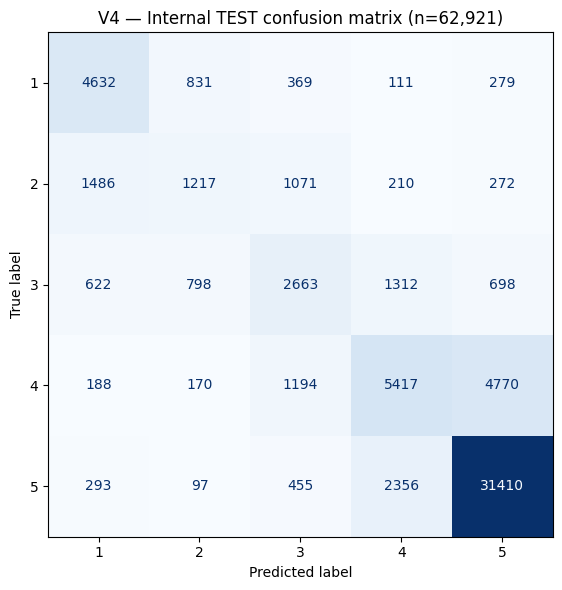

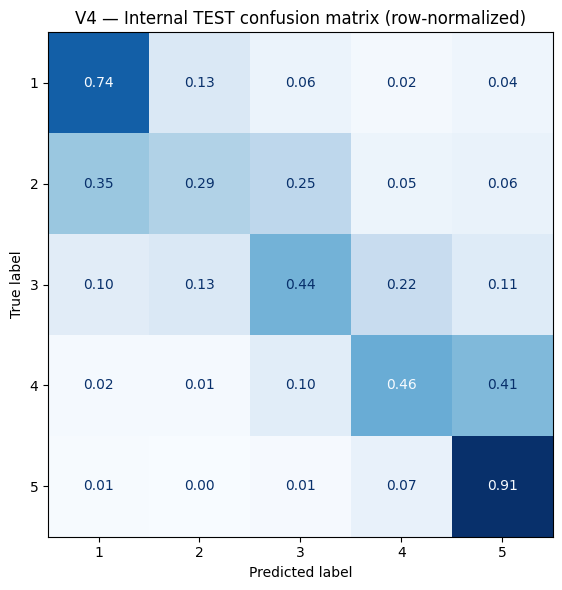

Saved all TEST reports, predictions and plots:
 - test_by_history_group.csv
 - test_classification_report.csv
 - test_confusion_matrix.csv
 - test_confusion_matrix.png
 - test_confusion_matrix_normalized.png
 - test_metrics.json
 - test_per_class_metrics.csv
 - test_predictions.csv


In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels).plot(
    ax=ax,cmap='Blues',values_format='d',colorbar=False
)
ax.set_title(f'V4 — Internal TEST confusion matrix (n={len(y_true):,})')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'test_confusion_matrix.png',dpi=170,bbox_inches='tight')
plt.show()

normalized_cm = confusion_matrix(y_true,predicted_ratings,labels=labels,normalize='true')
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix=normalized_cm,display_labels=labels).plot(
    ax=ax,cmap='Blues',values_format='.2f',colorbar=False
)
ax.set_title('V4 — Internal TEST confusion matrix (row-normalized)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'test_confusion_matrix_normalized.png',dpi=170,bbox_inches='tight')
plt.show()

print('Saved all TEST reports, predictions and plots:')
for filepath in sorted(OUTPUT_DIR.iterdir()):
    if filepath.is_file():
        print(' -',filepath.name)

## فایل‌های خروجی در Google Drive

در مسیری مانند زیر، هر بار اجرای ارزیابی یک پوشهٔ جدید می‌سازد:

`MyDrive/amazon_sentiment/experiments_history/20261105_165318_432545/test_evaluations/<UTC_TIMESTAMP>/`

فایل‌های مهم:

- `test_metrics.json`: معیارهای **Test** شامل Micro-F1، Macro-F1، Accuracy، MAE و NLL.
- `test_predictions.csv`: امتیاز واقعی و پیش‌بینی‌شدهٔ همهٔ 62,921 نمونه همراه با احتمال پنج کلاس، سابقهٔ کاربر و وزن مؤثر تاریخچه.
- `test_classification_report.csv` و `test_per_class_metrics.csv`: Precision/Recall/F1 هر کلاس.
- `test_confusion_matrix.csv` و دو تصویر PNG از ماتریس درهم‌ریختگی.
- `test_by_history_group.csv`: عملکرد روی کاربران بدون سابقه، با 1–2، 3–4 و 5+ نظر پیشین.

**مهم:** این **Test داخلی با برچسب** است که در فایل اصلی V4 با `RUN_TEST=False` اجرا نشده بود. این کد از `validation` برای محاسبهٔ نتایج نهایی استفاده نمی‌کند و به هیچ فایل Test خارجی بدون برچسب نیاز ندارد. نتیجه‌های عددی Test فقط پس از اجرای نوت‌بوک در حساب Drive خودتان تولید می‌شوند.